# Figure 3 — prior gene knowledge extends ExPert to perturbations absent from its training screens

Renders panels B–F and H–I from cached tables. `data/` = Fig. 3's plotting cache (written by `fig3.sbatch` STEP=data/zs/layout3, `fig3a_folds.sbatch`, `fig3a_seen.sbatch`, `fig3_doubles.sbatch`); `inputs/prior_screen/` = the deployment-panel prior screen (`bio/` and the `H4_full_p4` run), read through the screen's own loaders (`paper/analysis/readout/prior_screen/plot.py`, repo code). Panels go to `render/`, their source tables to `render/src/`.

Panels **A** (prior knowledge places a prototype for every gene) and **G** (doubles recovery) are hand-drawn schematics: no script draws them, so they are not rendered here.

In [1]:
import sys
from pathlib import Path
_paper = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts' / 'common').is_dir())
sys.path.insert(0, str(_paper / 'scripts' / 'common'))
import nbtools as nb                      # puts paper/scripts/*/ on sys.path

vs = nb.vizstyle()
DATA, INPUTS, OUT, SRC = nb.folders()     # data/ (cache), inputs/, render/, render/src/

In [2]:
import json
import pandas as pd
import fig3_plot as P
import fig3_doubles_plot as D
import fig4_pb_plot as fp

# style + the prior screen's loaders (P.PS); repo code, located relative to paper/
P.setup(vs, nb.PAPER / 'analysis' / 'readout' / 'prior_screen')
SCREEN, TAG = INPUTS / 'prior_screen', 'H4_full_p4'

## A — schematic (hand-drawn, not rendered)

## B — zero-shot retrieval per context, ID | OOD, across the 12 fold models

### How the panel B cache was made (not run here)

Panel B reads `data/fig3a_contexts.tsv` plus two JSON files per fold model, `data/folds/fig3a_fold{0..11}.json` and `data/folds/fig3a_seen_fold{0..11}.json`. Each cell line or donor group's row comes from the 12 Fig. 2 fold models, i.e. the v0.1.0 recipe retrained with one held-out context per fold. The figure therefore shows each context's spread across folds and marks the fold that held it out. All steps run from the repo root on SLURM.

1. **Contexts:** `fig3.sbatch STEP=zs` runs `fig3/fig3a_contexts.py`, which maps every dataset to its Fig. 1 context name (T-cell donors pooled per condition) and writes `fig3a_contexts.tsv`.
2. **Zero-shot rows**, `fig3a_folds.sbatch`, array 0–11, one task per fold, ~15 min and ≤ 23 GB each:
   - `paper/analysis/readout/cache_zs_queries.py` encodes the zero-shot DB (`database_perturbed_zs.h5ad`, perturbations no fold was trained on) with the fold's `model.pt`. It uses ≤ 25 cells per dataset × perturbation, needs ≥ 5, and writes `analysis_out/qcache/folds/ExPert_fold{F}_zs.npz`.
   - `paper/analysis/readout/prior_screen/screen.py panels --shipped-fill --zs-panel full --reps 20` scores those queries against the fold model's **shipped** zero-shot fill (`prior_missing_T`, 19,895 candidates) per context. The null is 20 row-shuffled twins of the fill. The recipe rows are checked against EFFGATE3's prior-screen capture.
   - Output: `fig3a_fold{F}.json`.
3. **All seen perturbations** (the grey reference), `fig3a_seen.sbatch`, array 0–11, 65–125 min and ~100–145 GB each:
   - `fig3/fig3a_seen.py cap` caps the fold's ID-test and OOD-test splits at 25 cells per dataset × perturbation.
   - `paper/analysis/readout/cache_queries.py` encodes them from the full DB (`database_perturbed.h5ad`).
   - `fig3a_seen.py score` ranks them on the same 19,895-row table.
   - Output: `fig3a_seen_fold{F}.json`.

**Inputs:**
- the 12 fold checkpoints (`model.pt` per fold);
- DB `_zs` for step 2;
- the full DB plus `splits/full/fold_{F}` for step 3;
- the EFFGATE3 text bank and prior-screen capture (`paper/analysis/readout/prior_screen/paths.sh`).

Step 3 needs the full 131 GB perturbed DB, so `fig3a_seen_fold*.json` is deposited as a cache only.

  wrote fig3b_zeroshot.svg / .png


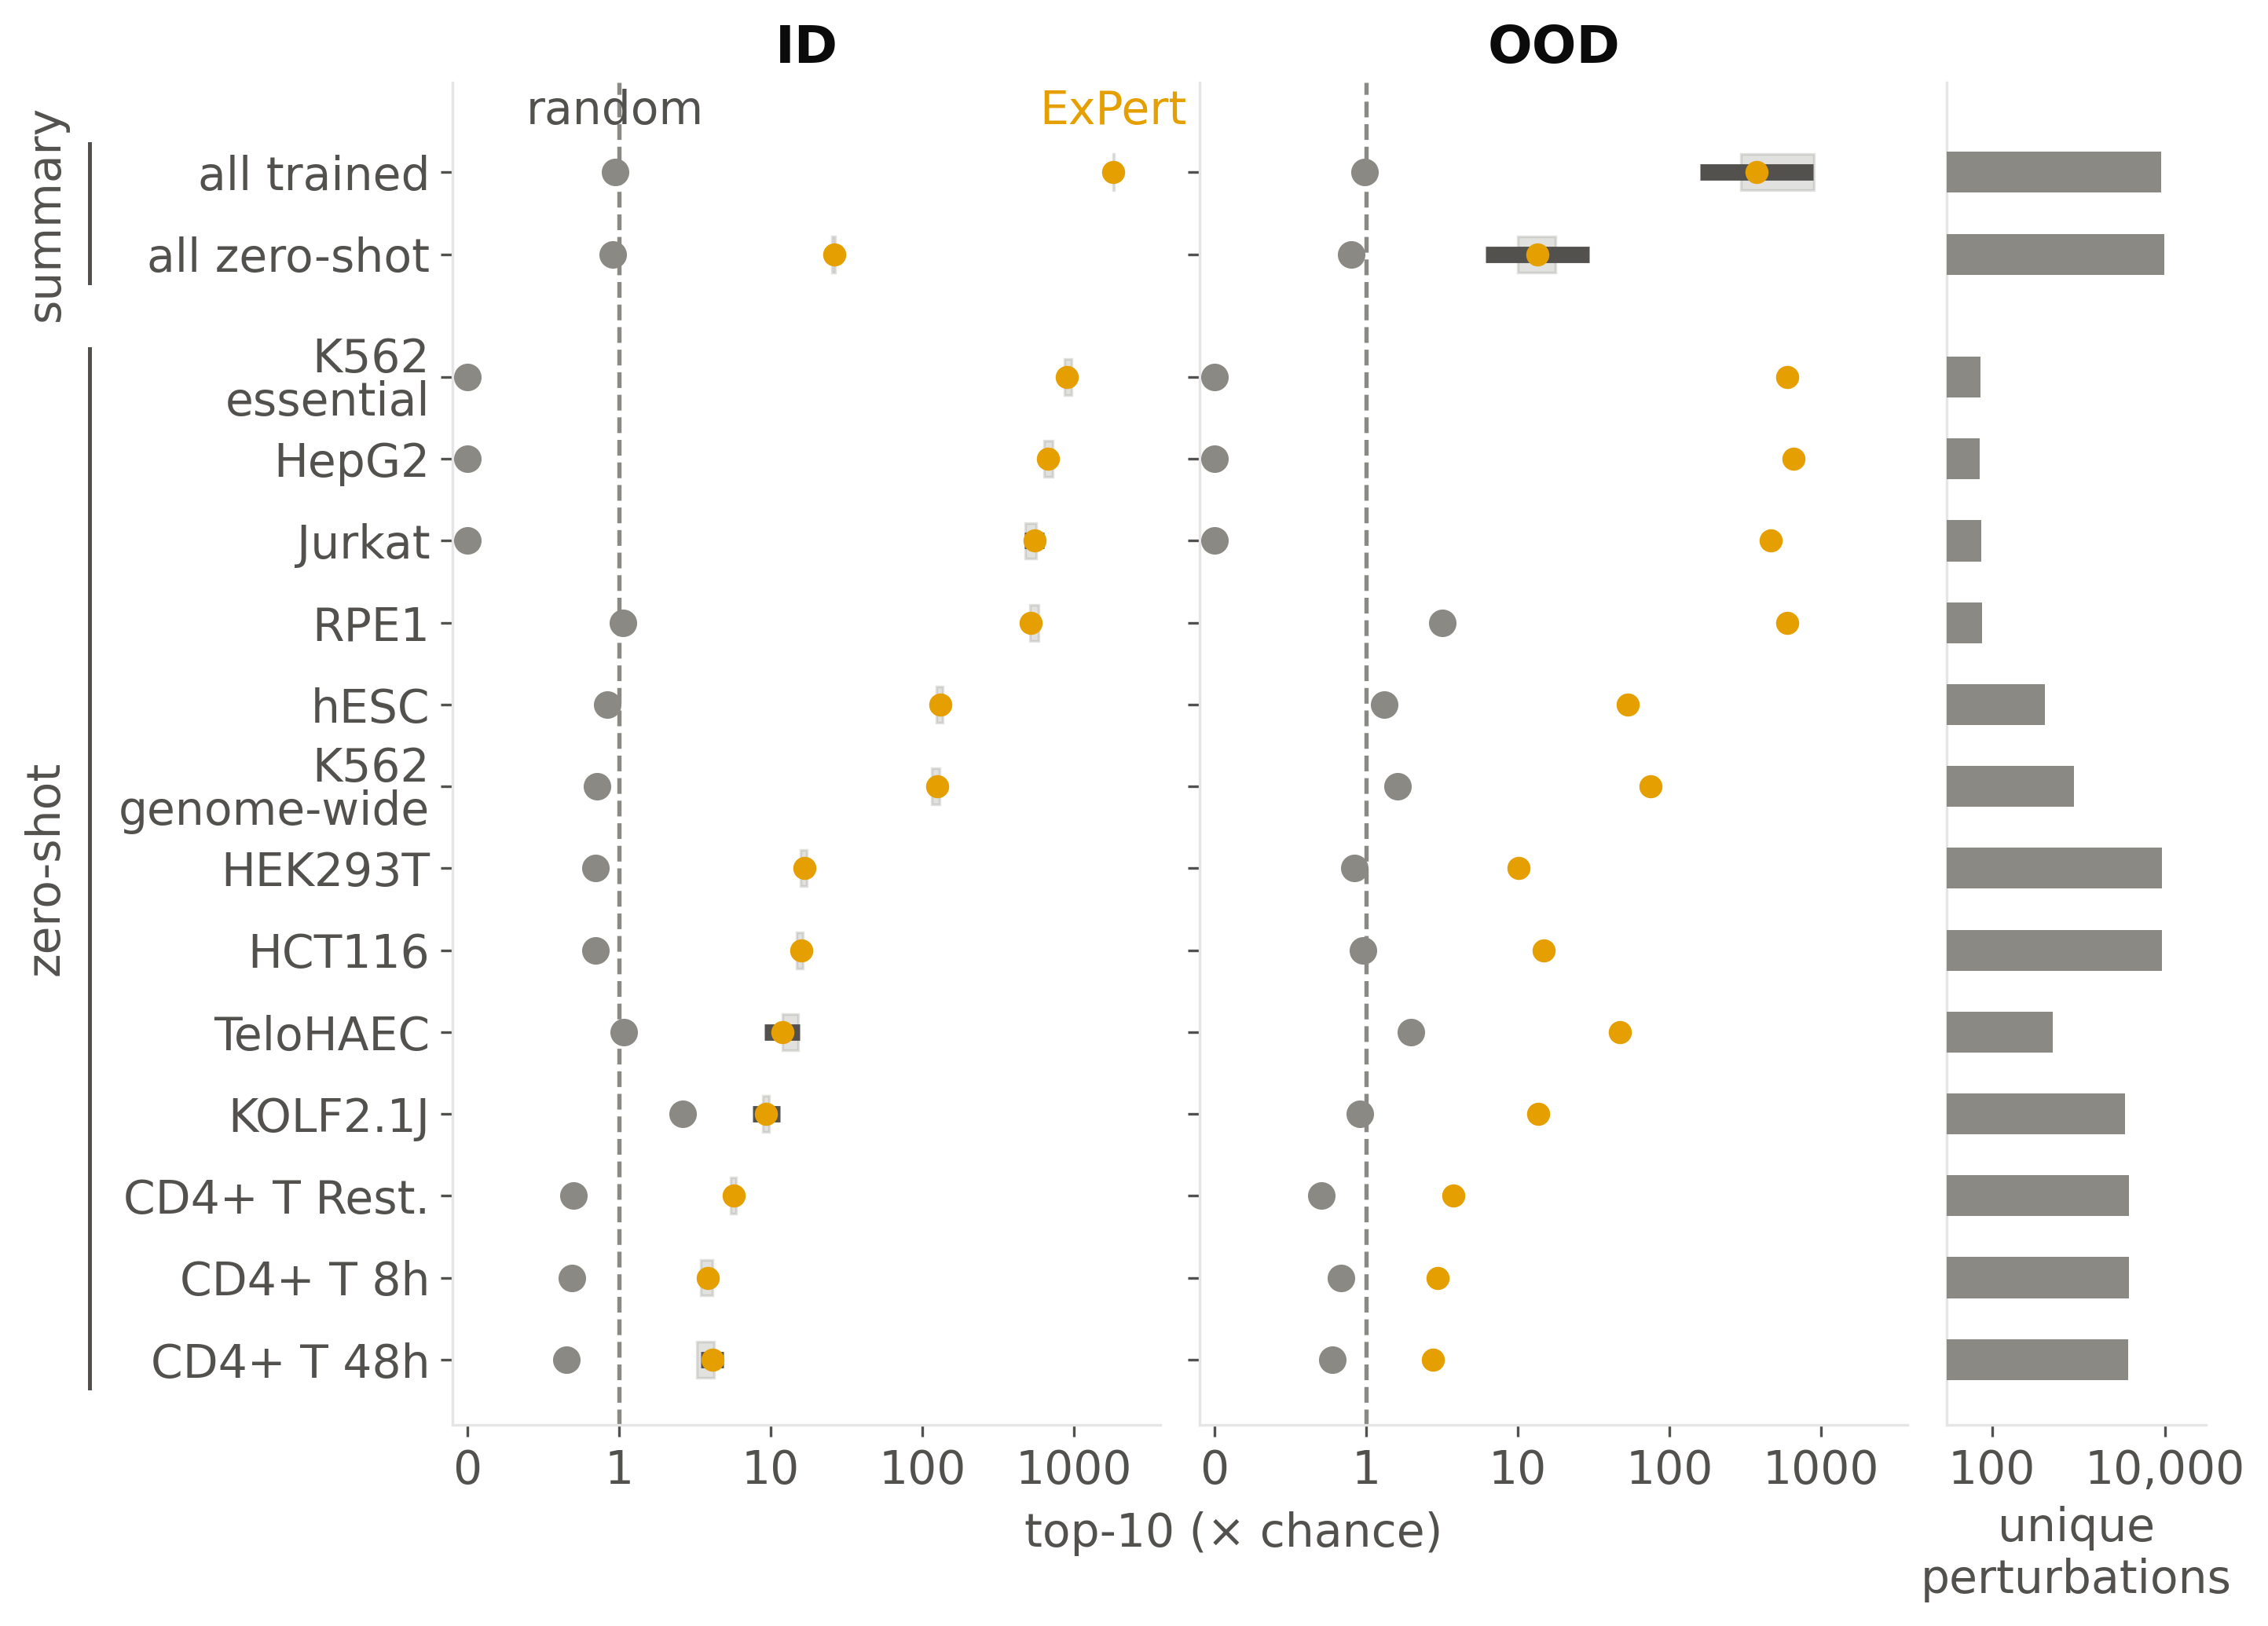

In [3]:
P.panel_a_side(DATA, OUT)
nb.show(OUT, 'fig3b_zeroshot')

## C — circular Ward tree of the trained prototypes, each zero-shot fill placed beside its nearest trained prototype

  wrote fig3c_circular_tree.svg / .png


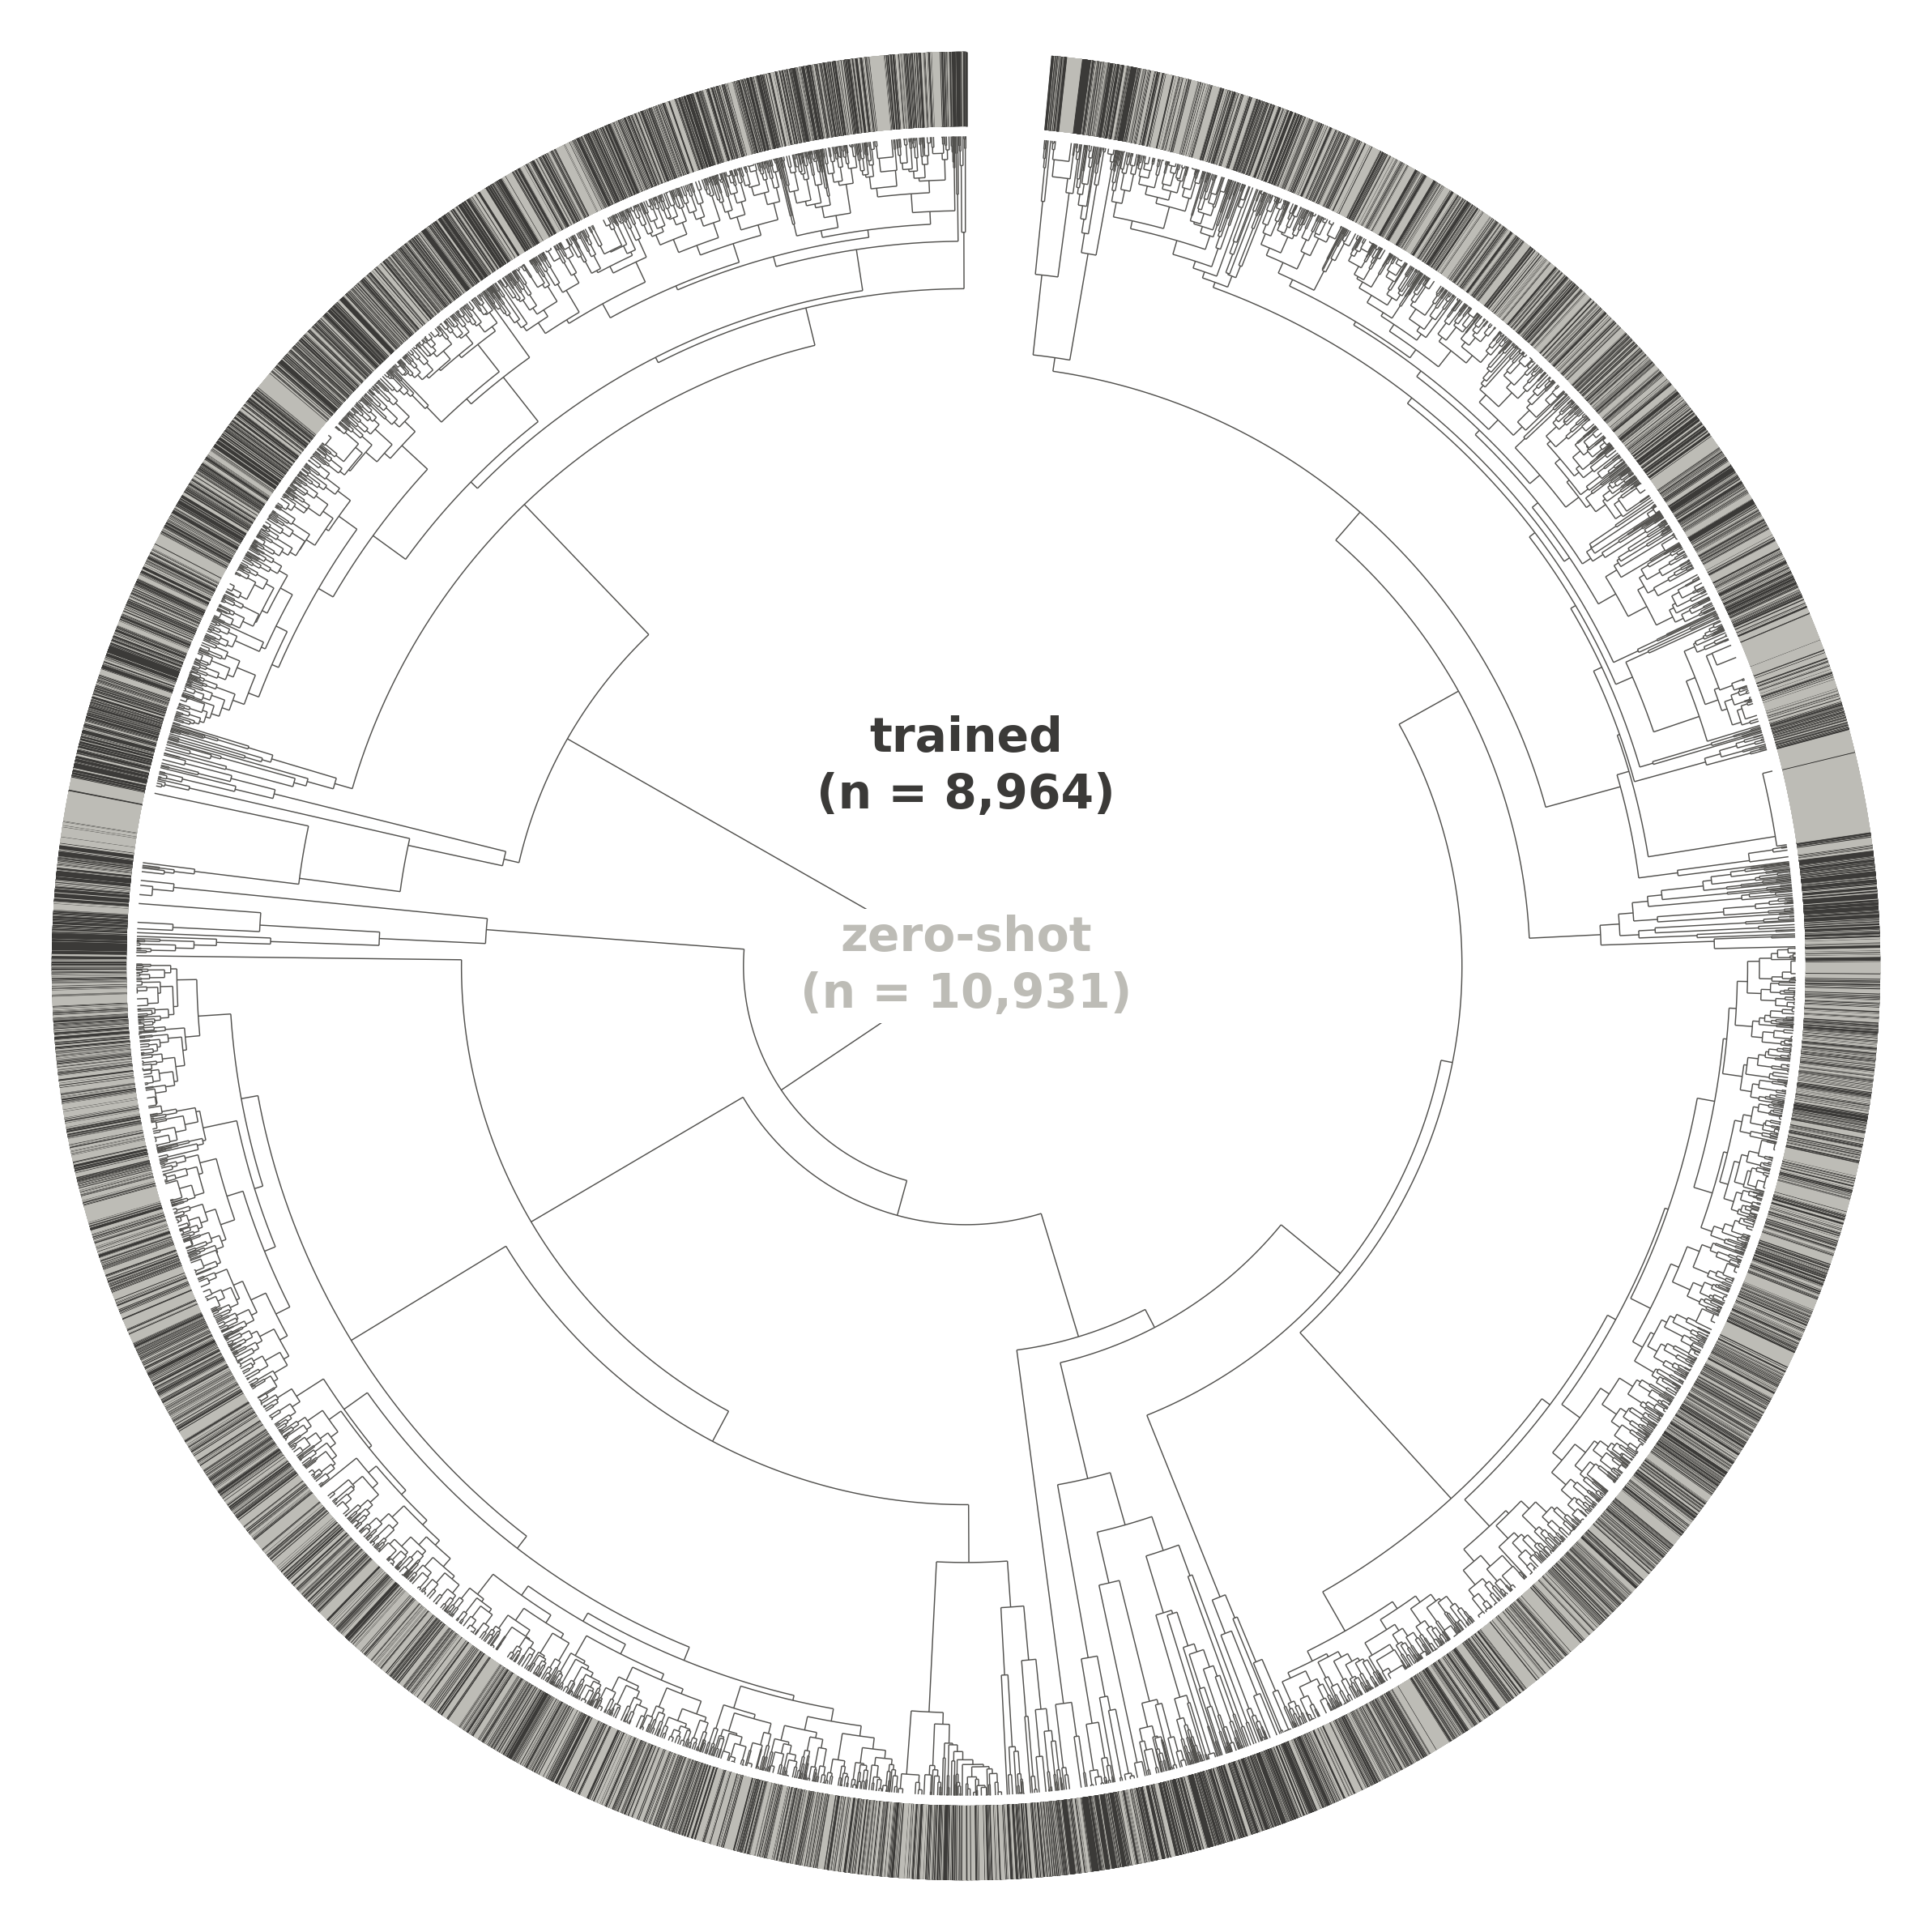

In [4]:
P.KIND = {'trained': ('trained', '#3b3a38'), 'fill': ('zero-shot', '#bdbcb6')}   # as in main()
P.panel_b_tree(DATA / 'b_place', OUT, 'fig3c_circular_tree', src=SRC)
nb.show(OUT, 'fig3c_circular_tree')

## D — generation of the gene text embeddings (source → writer → encoder)

  wrote fig3d_text_generation.svg / .png


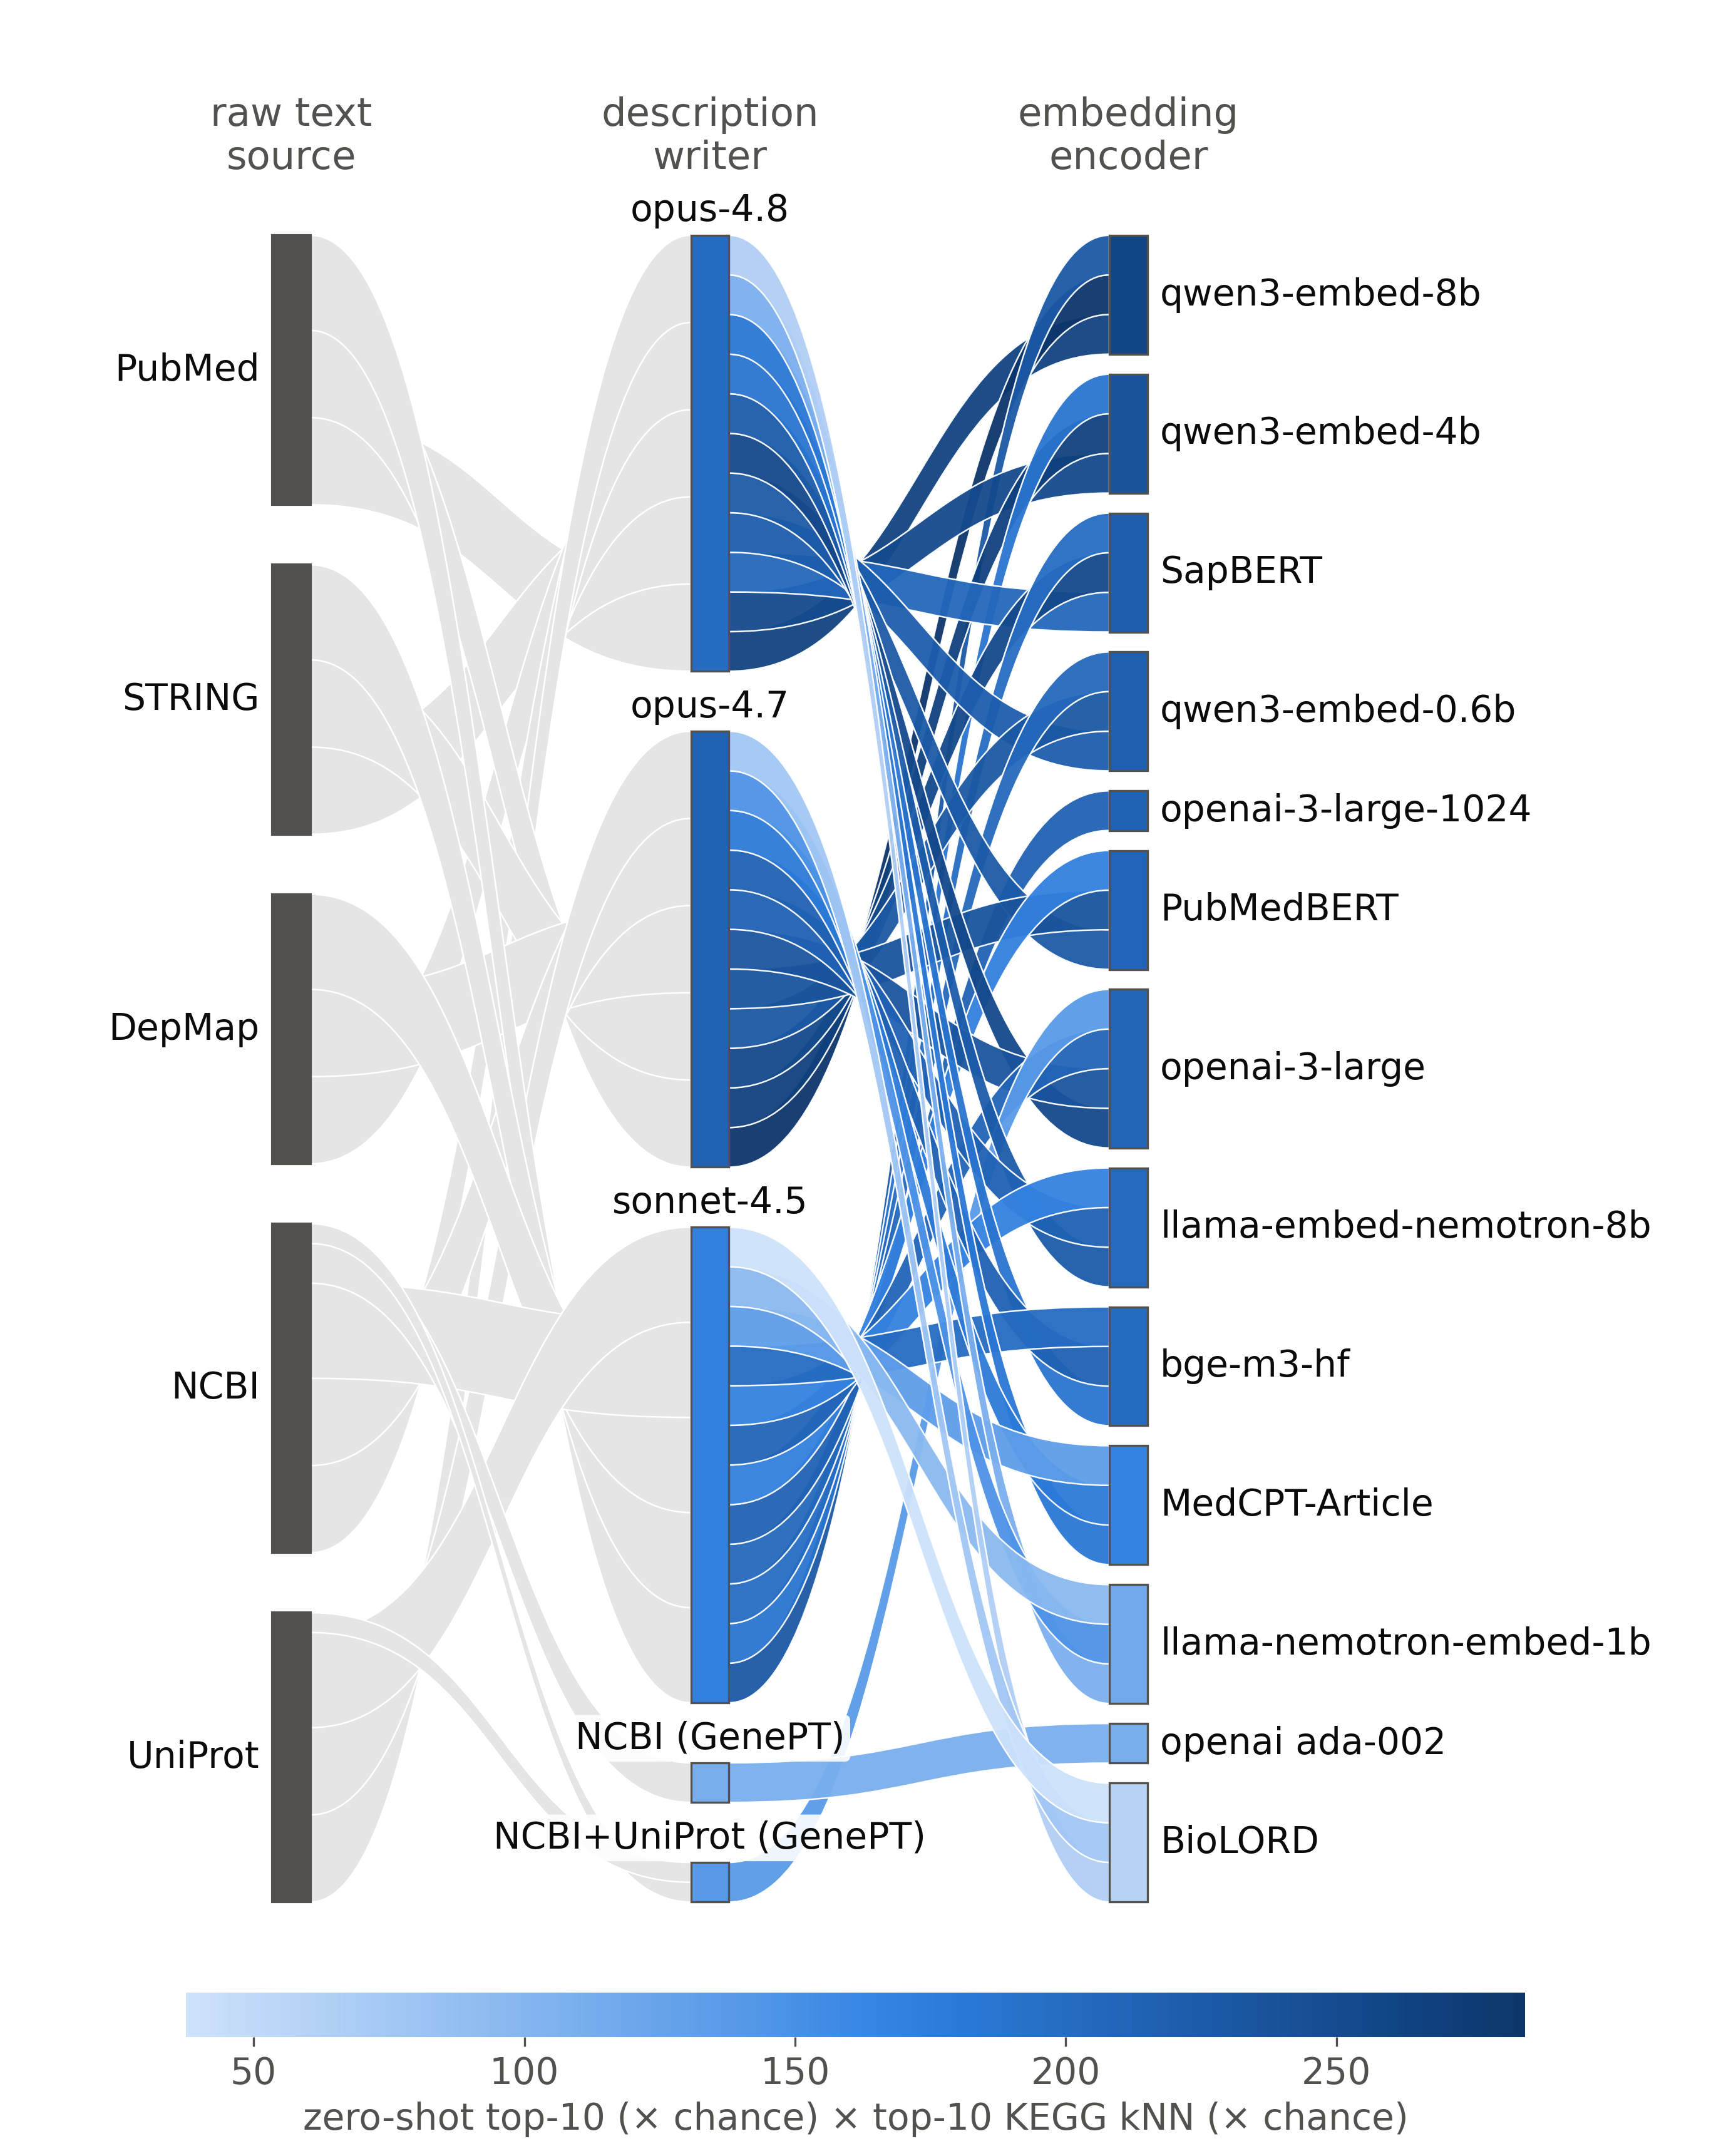

In [5]:
bio, zs = P.PS.collect(str(SCREEN), TAG, P.METRIC)
P.panel_d(bio, zs, DATA, OUT, src=SRC)
nb.show(OUT, 'fig3d_text_generation')

## E — prior quality (KEGG neighbour lift) predicts zero-shot retrieval

  wrote fig3e_prior_quality.svg / .png


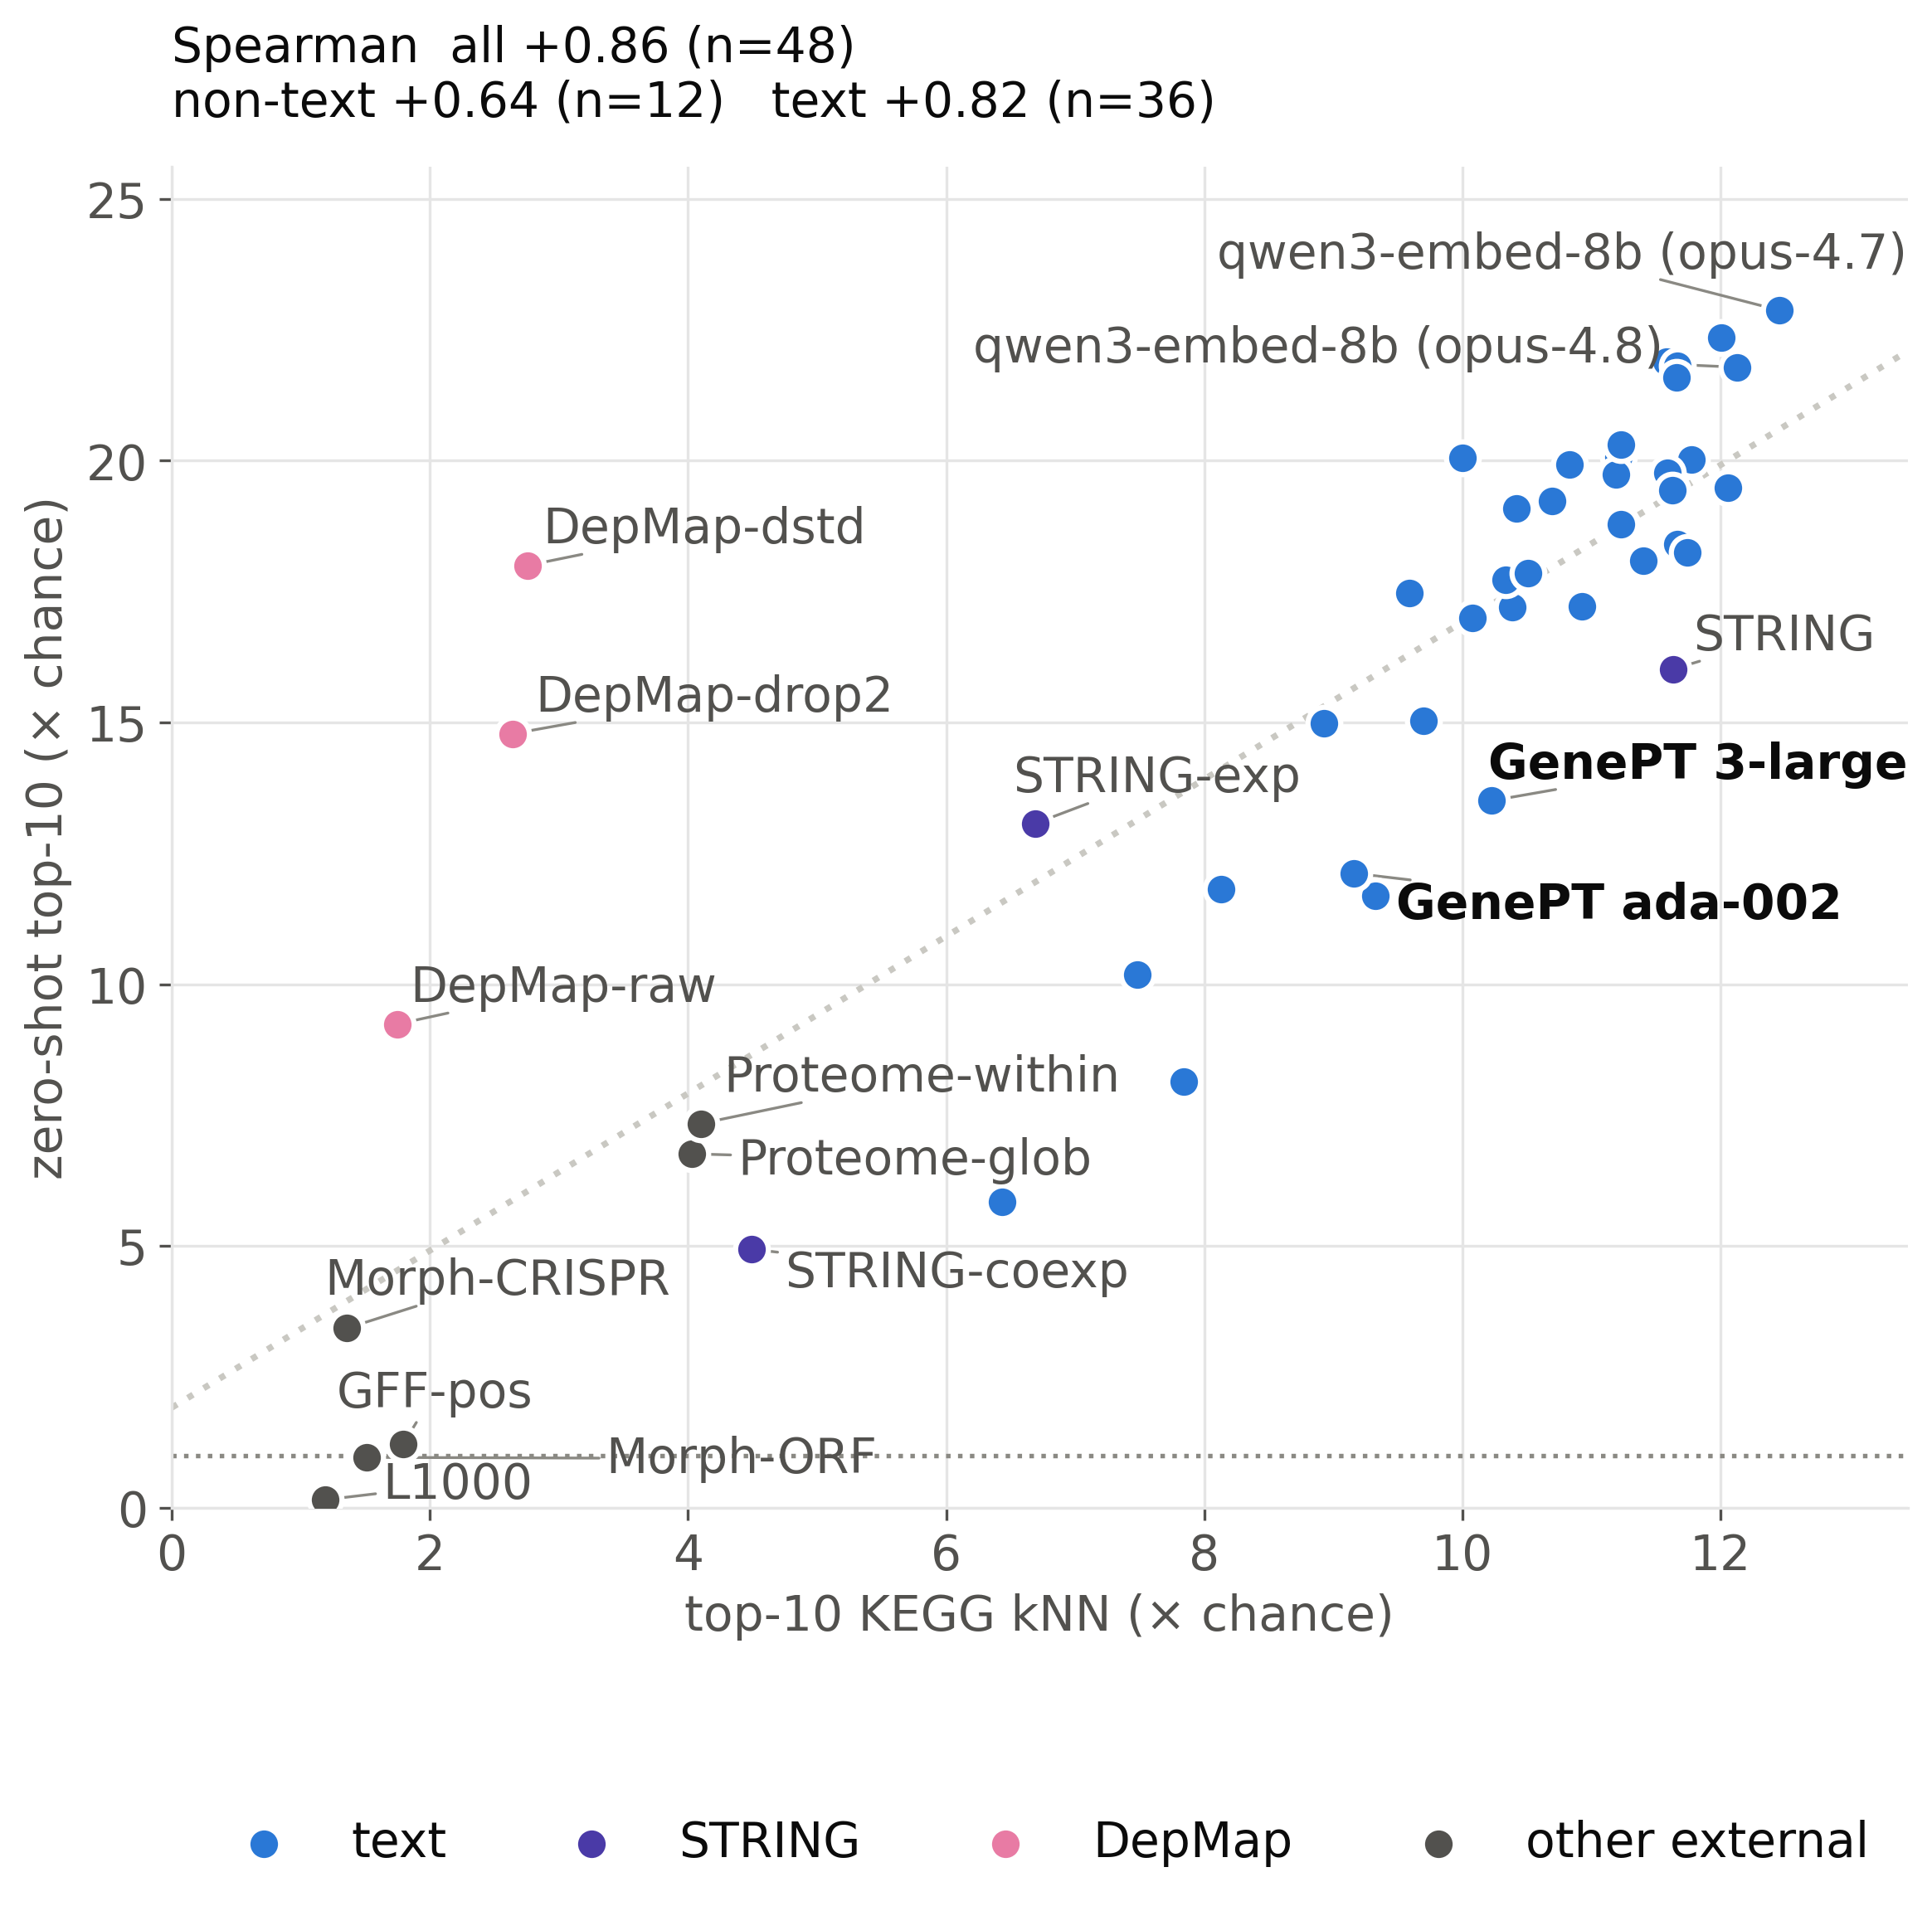

In [6]:
P.panel_e(bio, zs, DATA, OUT, src=SRC)
nb.show(OUT, 'fig3e_prior_quality')

## F — combining priors: every subset of the ten best single priors

  wrote fig3f_prior_combinations.svg / .png


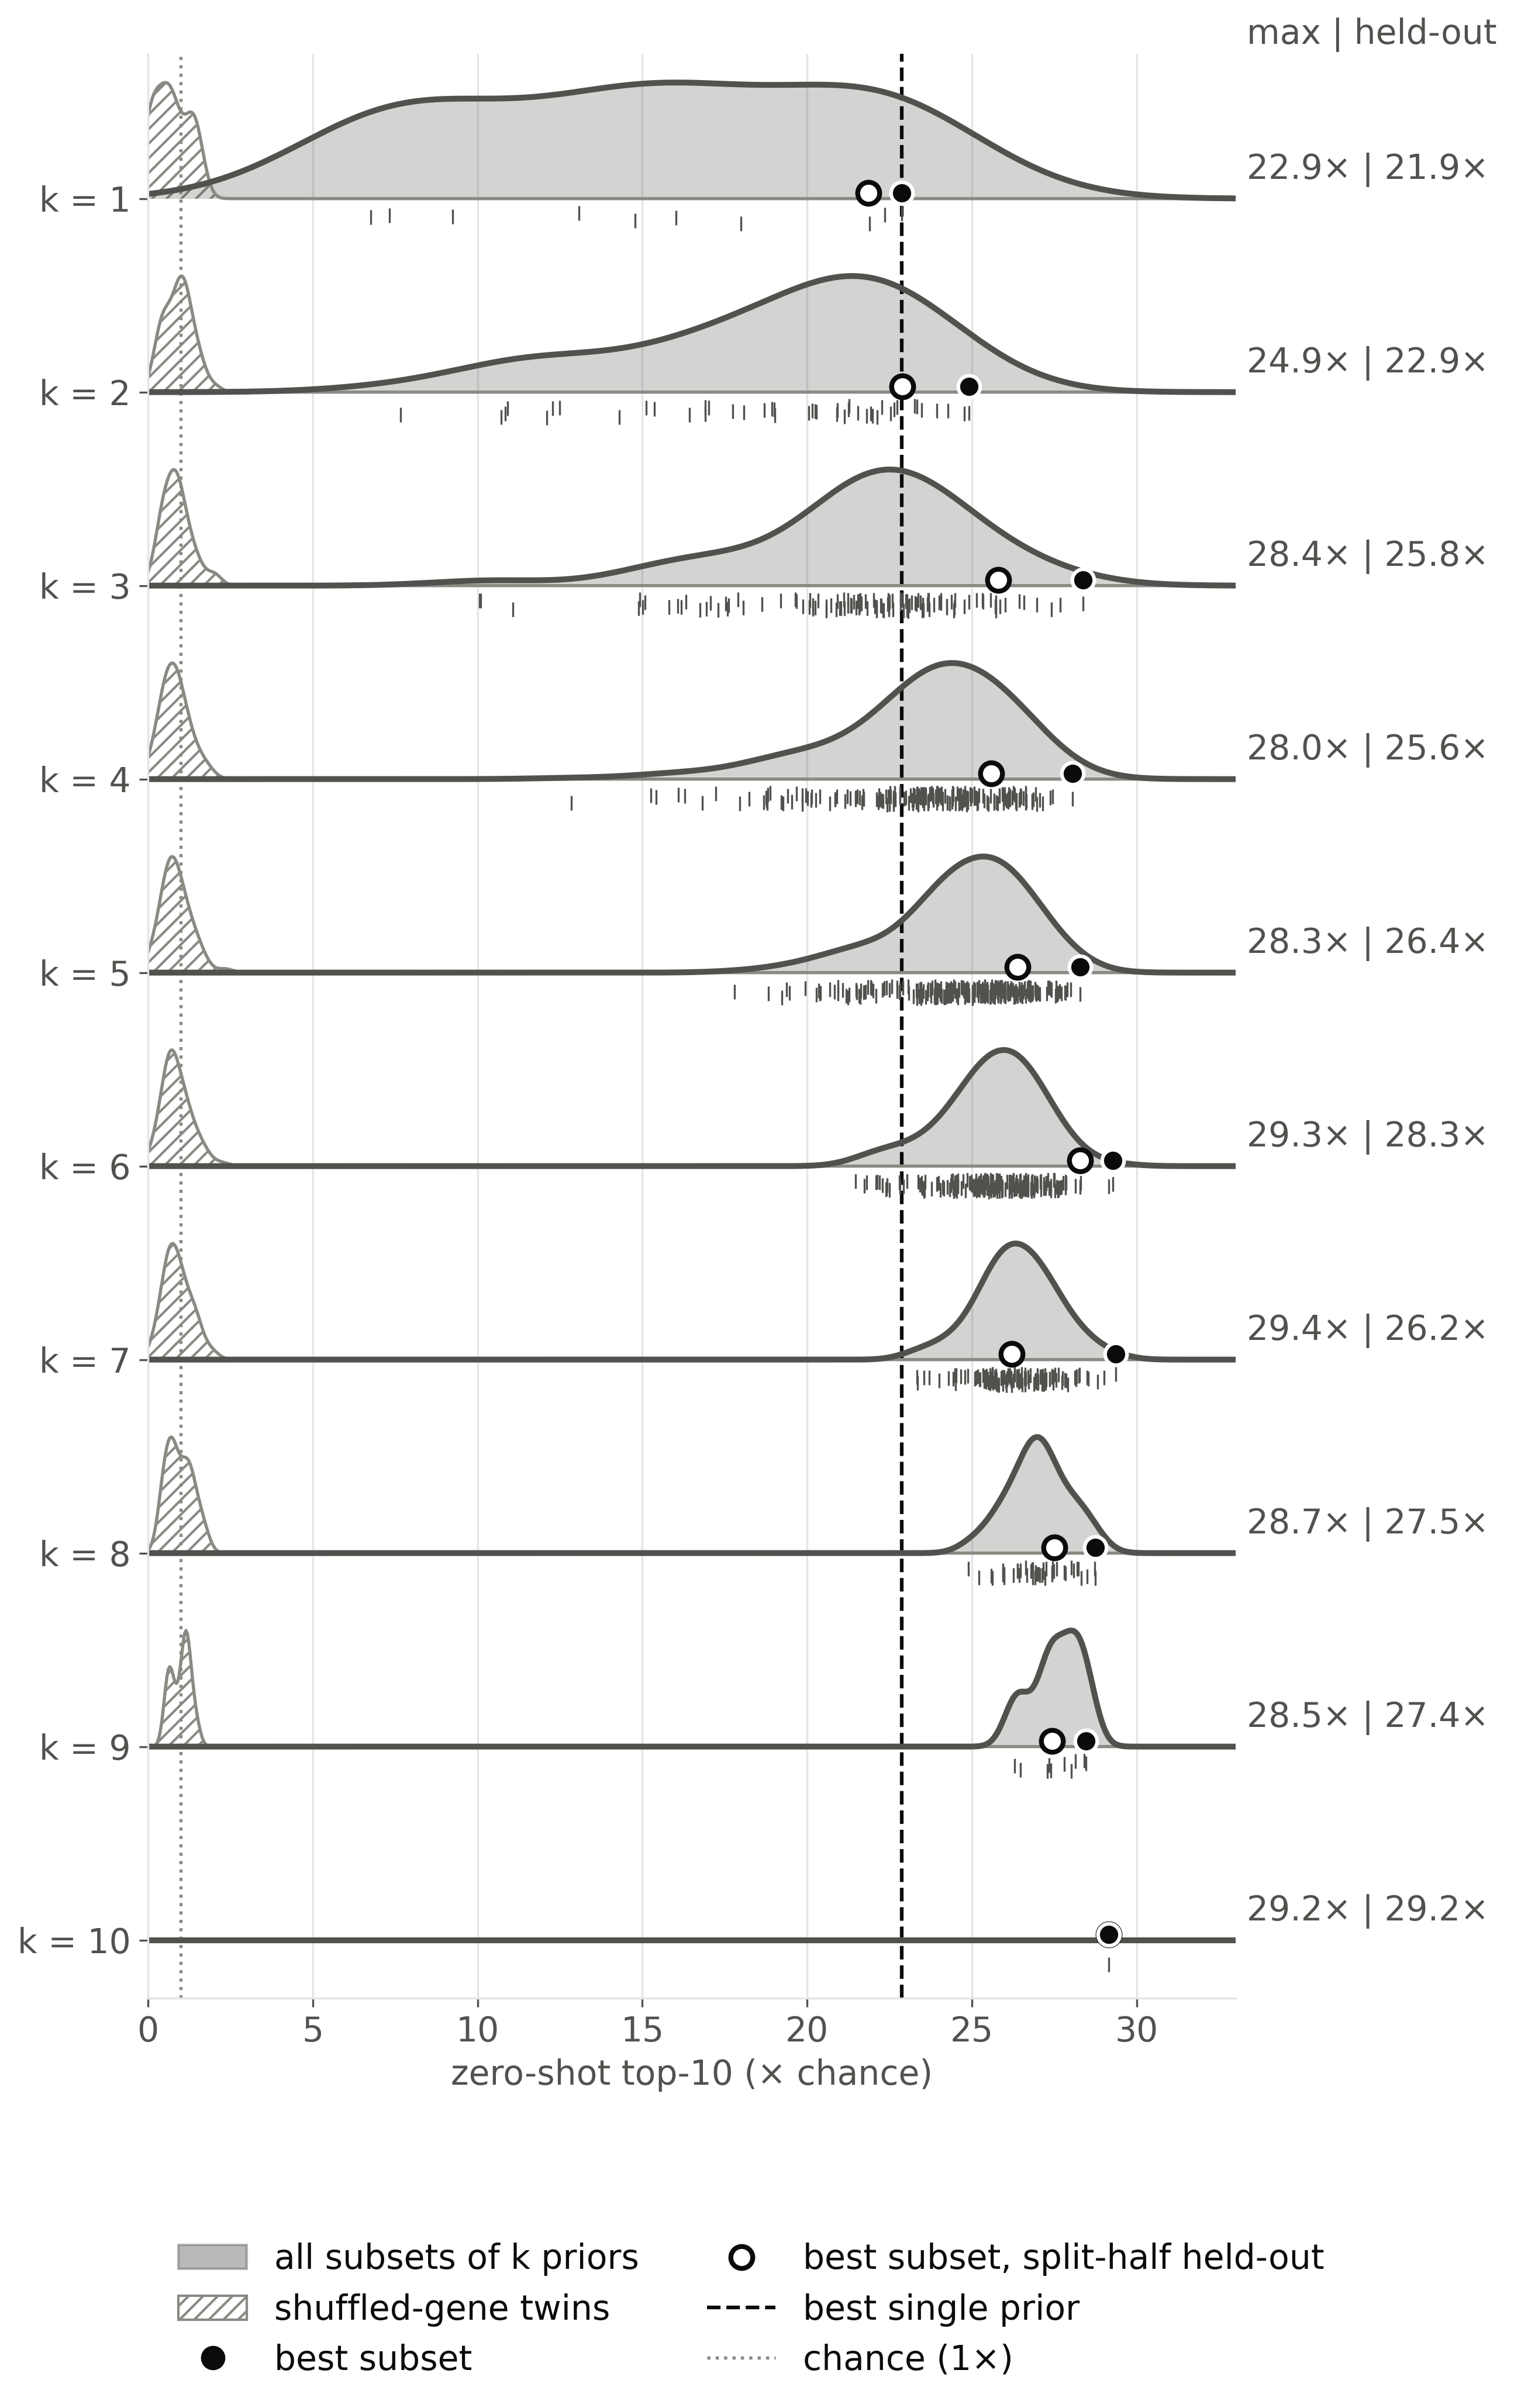

In [7]:
cb, pool = P.PS.load_combos(str(SCREEN / TAG))
P.panel_f(cb, pool, DATA, OUT, src=SRC)
nb.show(OUT, 'fig3f_prior_combinations')

## G — schematic (hand-drawn, not rendered)

## H — combinatorial loss-of-function recovery (either gene in the top k of 8,347 candidates)

Drawn by `fig3_doubles_plot.py` (`fig3_doubles_plot.sbatch`), which runs as its own process with `fig4_pb_plot`'s style.

  wrote fig3h_doubles_loss.svg / .png


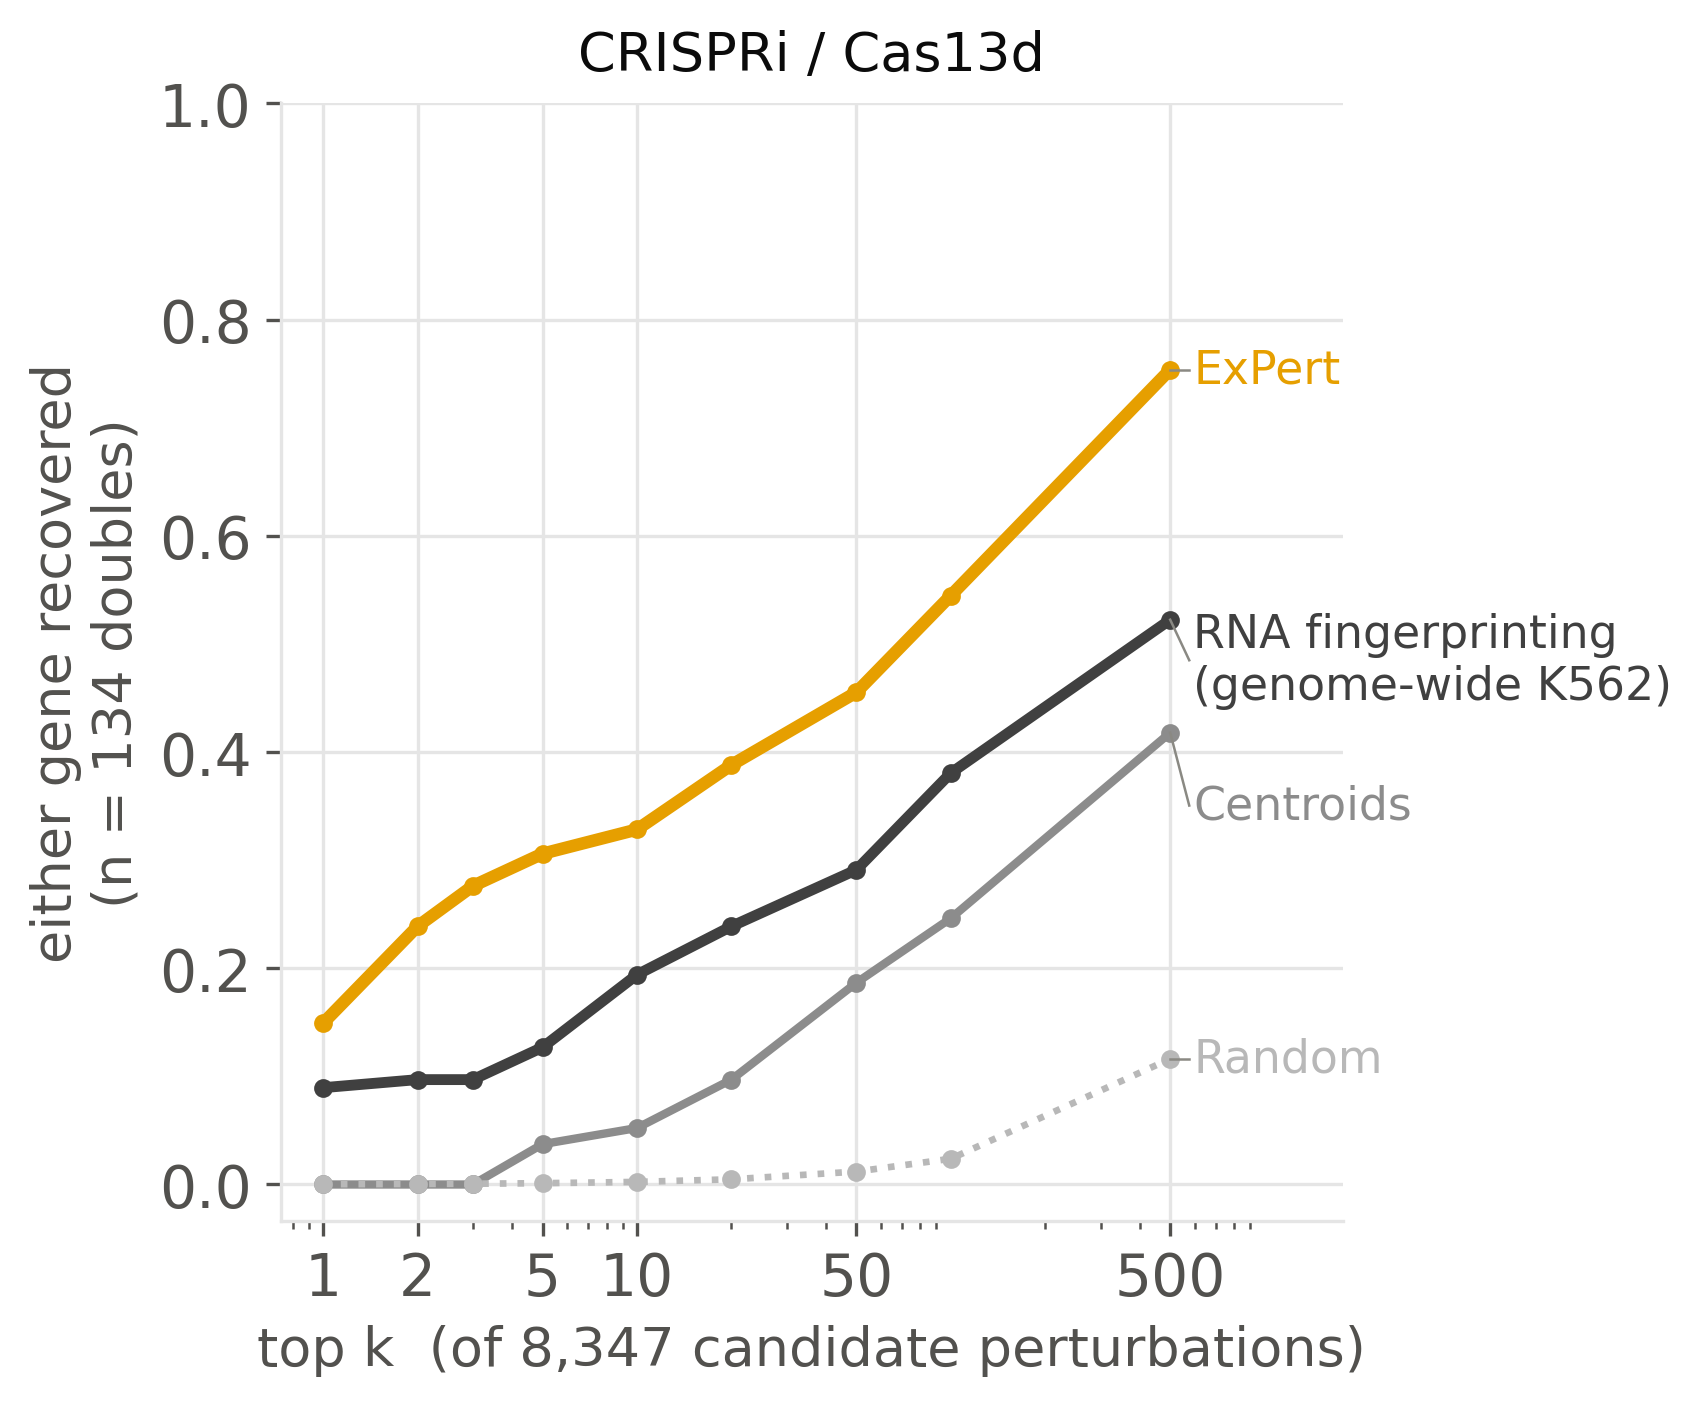

In [8]:
import matplotlib
matplotlib.rcdefaults()   # the sbatch runs this script as its own process: start from matplotlib defaults
fp.setup(str(nb.STYLE))
fp.SRC_DIR = str(SRC)
D.plt, D.matplotlib = fp.plt, fp.matplotlib
C = pd.read_csv(DATA / 'doubles' / 'ourgwps_doubles_curves.csv')
meta = json.load(open(DATA / 'doubles' / 'ourgwps_meta.json'))
D.panel(C, meta, 'loss', 'in_panel', 'any', OUT, '')     # -> fig3h_doubles_loss
nb.show(OUT, 'fig3h_doubles_loss')

## I — combinatorial gain-of-function recovery, as in H

  wrote fig3i_doubles_gain.svg / .png


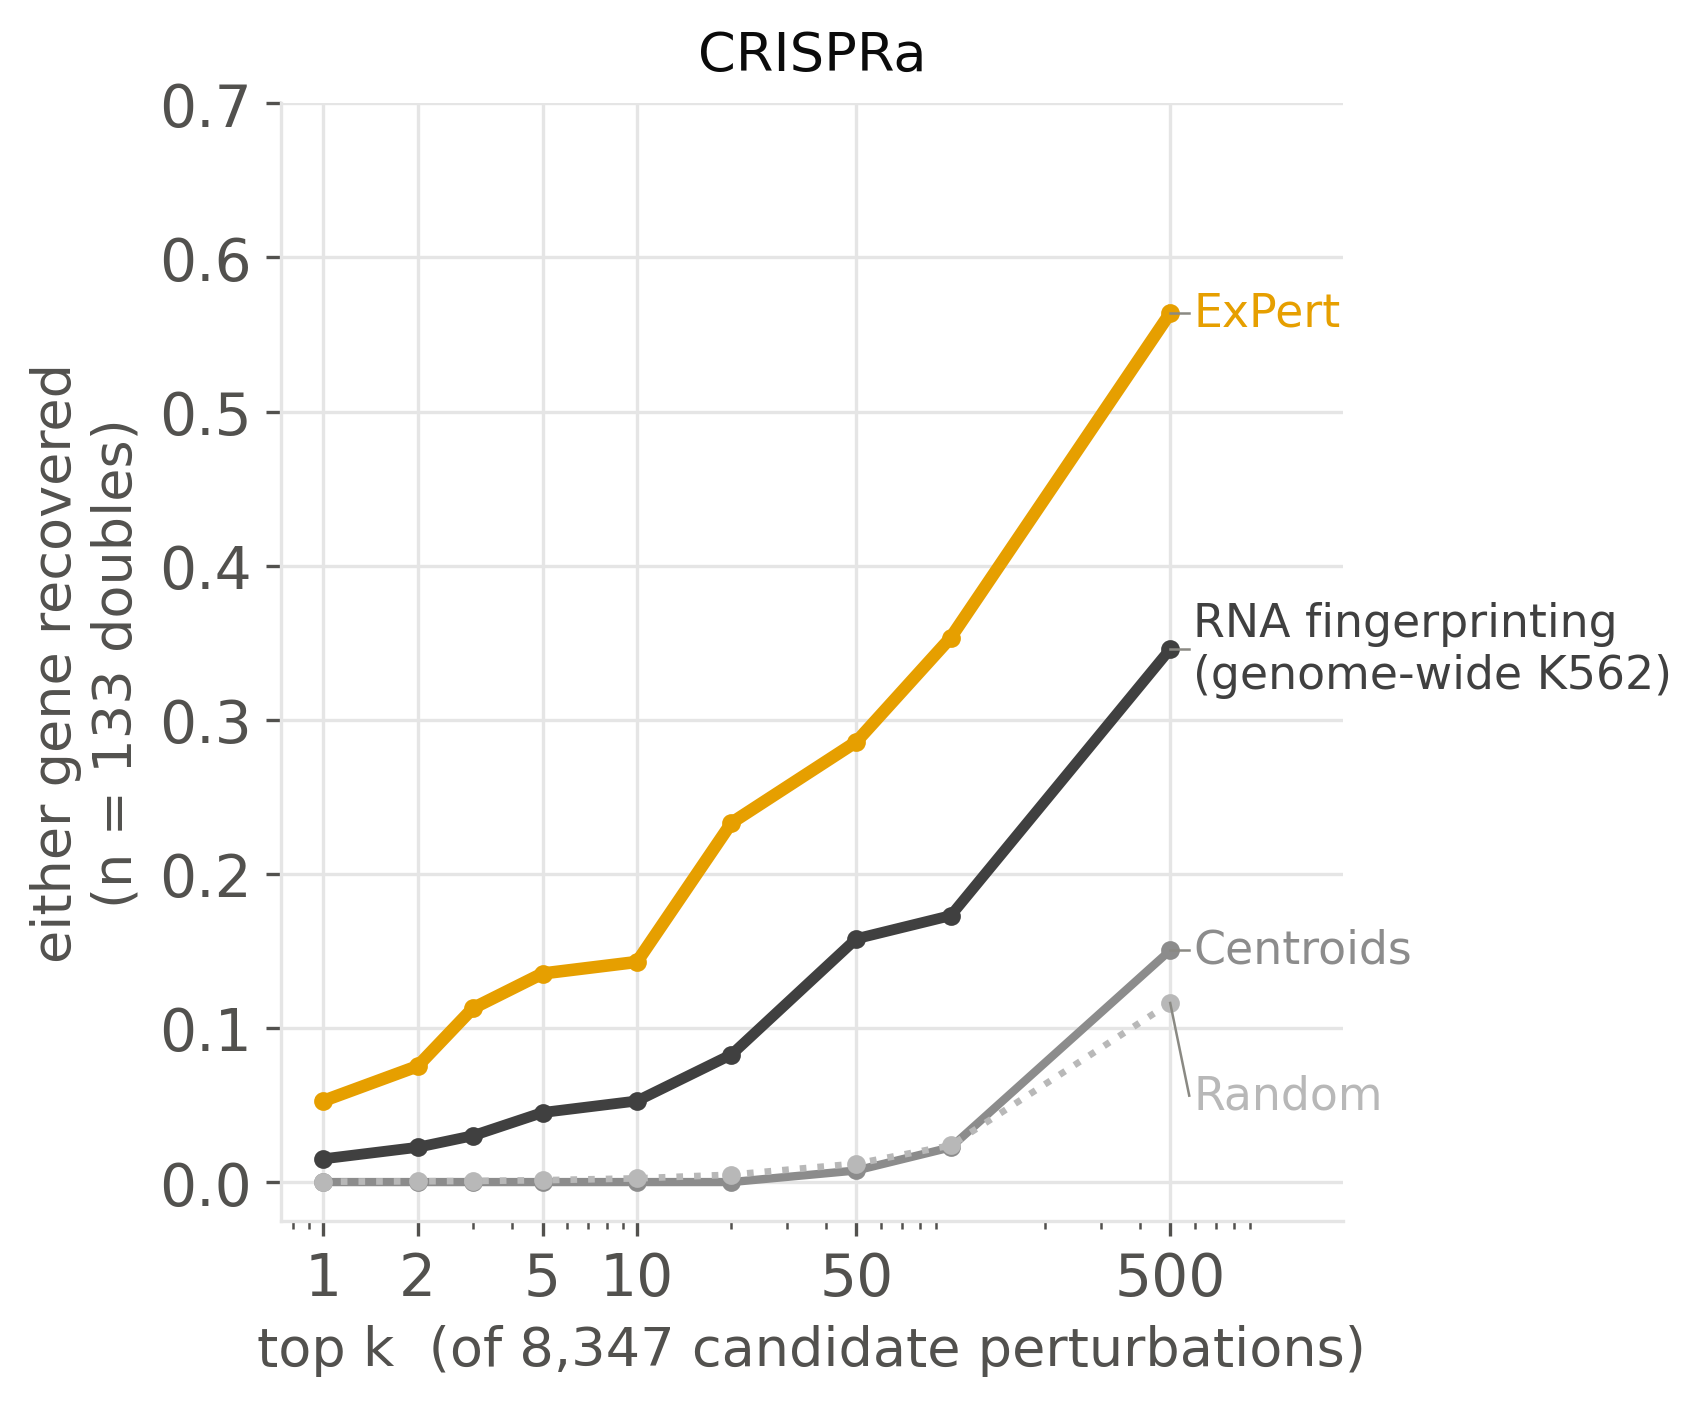

In [9]:
D.panel(C, meta, 'gain', 'in_panel', 'any', OUT, '')     # -> fig3i_doubles_gain
nb.show(OUT, 'fig3i_doubles_gain')